# Exercise 5 — Recovering an AGN flare

*Covers notebooks 06. Difficulty: ★★★★☆*

A nucleus brightens by a few tenths of a magnitude over days. Inject it into a real Gaia field, render WCC frames, and see how well differential photometry against field stars recovers it.

*Renders 2048 px frames: ~10 s each, ~1 GB. Restart the kernel when done.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import simple_norm
from wcc_etc import plot_image_mpl
from wcc_sim import simulate_field
from wcc_sim.catalog import query_gaia
from wcc_phot import run_photometry
from wcc_phot.centroid import centroid_stars

### 5.1 — The field and the injected nucleus

Load the cached Gaia field at (RA, Dec) = (300°, +30°) (60" radius), add a row at the field centre
with `source_id=1` and G = 18 (a host-free, stellar-SED stand-in for an AGN), and render eight 60 s
frames on a 2048 px subarray in which the injected source follows the flare
`dmag = [0, 0, -0.10, -0.25, -0.35, -0.30, -0.20, -0.10]`. Show the first frame with the target
marked.

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


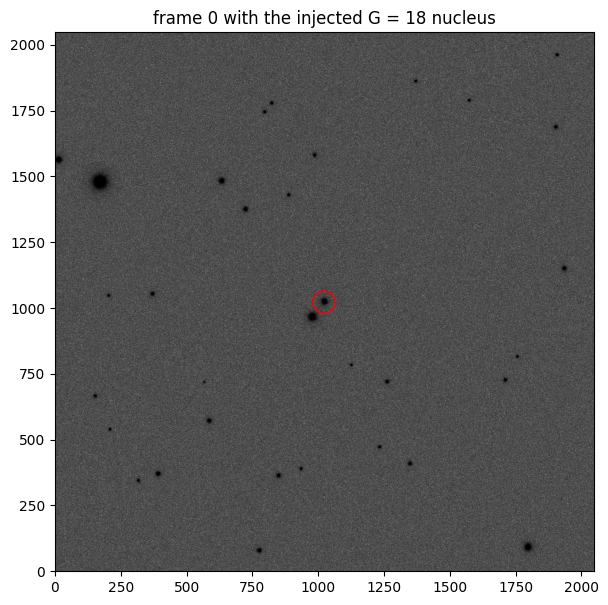

In [2]:
RA, DEC = 300.0, 30.0
cat = query_gaia(RA, DEC, radius_arcsec=60, mag_limit=21.0, cache_dir="gaia_cache")
row = {k: np.nan for k in cat.colnames}
row.update(source_id=1, ra=RA, dec=DEC, phot_g_mean_mag=18.0)
cat.add_row(row)
dmag = np.array([0.0, 0.0, -0.10, -0.25, -0.35, -0.30, -0.20, -0.10])
frames = []
for k, dm in enumerate(dmag):
    cat["phot_g_mean_mag"][-1] = 18.0 + dm
    frames.append(simulate_field(RA, DEC, sensorfilter="zwo:r", focus=0, exptime=60, seed=k, shape=(2048, 2048), catalog=cat))
c = frames[0].catalog
x0, y0 = [float(c[c["source_id"] == 1][k][0]) for k in ("x", "y")]
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(frames[0].image_e, origin="lower", cmap="gray_r", norm=simple_norm(frames[0].image_e, "asinh", percent=99.7))
ax.plot(x0, y0, "o", ms=16, mfc="none", mec="r"); ax.set_title("frame 0 with the injected G = 18 nucleus")
plt.show()

### 5.2 — Recover the flare

Run `run_photometry` on the eight frames (target 1, ten comparison stars, epochs 0.5 d apart) and
plot the recovered magnitude change with error bars over the injected one. Report the residual RMS
and the median propagated error in mmag, and list any flagged epochs.

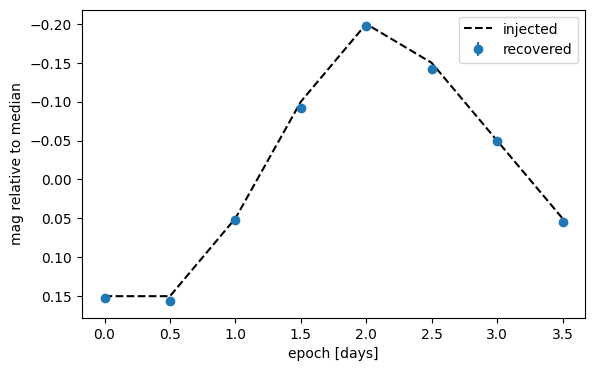

residual RMS 2.7 mmag, median error 3.3 mmag; flagged epochs: [4]


In [3]:
res = run_photometry(frames, target=1, method="aperture", n_ref=10, times=np.arange(len(dmag)) * 0.5)
lc = res.lightcurve
rec = -2.5 * np.log10(lc["rel_flux_norm"]); rec_err = 2.5 / np.log(10) * lc["rel_flux_norm_err"] / lc["rel_flux_norm"]
inj = dmag - np.median(dmag)
flagged = np.unique(res.measurements["frame"][res.measurements["flags"] != 0])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(lc["time"], inj, "k--", label="injected"); ax.errorbar(lc["time"], rec, yerr=rec_err, fmt="o", label="recovered")
ax.invert_yaxis(); ax.set(xlabel="epoch [days]", ylabel="mag relative to median"); ax.legend()
plt.show()
print(f"residual RMS {1e3 * np.std(np.asarray(rec - inj)):.1f} mmag, median error {1e3 * np.median(rec_err):.1f} mmag; flagged epochs: {flagged.tolist()}")

> ✏️ **Before you run the next cell:** by how much does the per-frame precision degrade from G = 18 to G = 20: a factor 1.5, 2.5 or 6? Write your guess down (or put it in the room poll), then run.

### 5.3 — Precision versus nucleus magnitude

For G = 17, 18, 19, 20, render three constant-brightness frames each and take the median
propagated error per frame as the precision. Plot it against magnitude. (This takes a minute or
two: ~10 s per frame.)

G = 17: nan mmag per 60 s frame (3 frames flagged)


G = 18: 3.4 mmag per 60 s frame


G = 19: 5.2 mmag per 60 s frame


G = 20: 8.4 mmag per 60 s frame


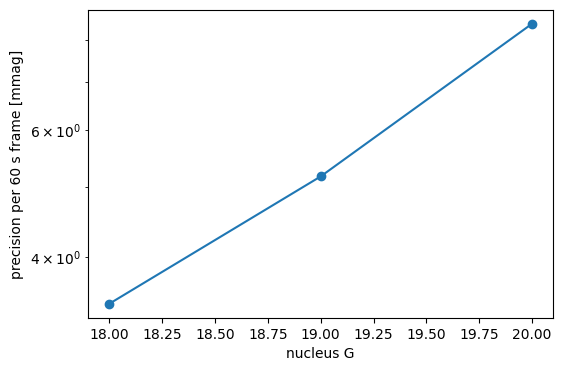

In [4]:
mags = [17, 18, 19, 20]
prec = []
for m in mags:
    cat["phot_g_mean_mag"][-1] = m
    fr = [simulate_field(RA, DEC, sensorfilter="zwo:r", focus=0, exptime=60, seed=100 + k, shape=(2048, 2048), catalog=cat) for k in range(3)]
    r = run_photometry(fr, target=1, n_ref=10)
    good = r.lightcurve["flags"] == 0
    err = r.lightcurve["rel_flux_norm_err"] / r.lightcurve["rel_flux_norm"]
    prec.append(1e3 * 2.5 / np.log(10) * np.median(err[good]) if good.any() else np.nan)
    print(f"G = {m}: {prec[-1]:.1f} mmag per 60 s frame" + ("" if good.all() else f" ({int((~good).sum())} frames flagged)"))
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(mags, prec, "o-"); ax.set(xlabel="nucleus G", ylabel="precision per 60 s frame [mmag]")
plt.show()

> 🤖 **Ask Jupyter AI:** *Replace the hand-written dmag array by a tidal disruption event: a rise over 2 epochs to a peak 0.5 mag brighter, then a t^(-5/3) decay over 10 epochs spaced 2 days apart. Regenerate the frames and rerun 5.2.*
>
> Then ask it how to add the host galaxy as a SersicComponent under the nucleus, and what that does to the aperture photometry.

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/wcc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*